# `fig-intro-off-the-shelf`: OLS treatment-effect error of off-the-shelf generative LLMs and decision models on the Vaccines subsample

In [6]:
from pathlib import Path
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ASSET_NAME = "fig-intro-off-the-shelf"
ASSET_DIR = Path.cwd()
PAPER_DIR = ASSET_DIR.parent
if not (PAPER_DIR / "microdata_analysis.py").is_file():
    raise FileNotFoundError(f"Open this notebook from manuscript-training-assets/; {PAPER_DIR} has no microdata_analysis.py")
if str(PAPER_DIR) not in sys.path:
    sys.path.insert(0, str(PAPER_DIR))

import microdata_analysis as ma

print(f"Outputs go to {ASSET_DIR / ASSET_NAME}.*")

import matplotlib.lines
import matplotlib.patches

Outputs go to /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-intro-off-the-shelf.*


## Labels and formatting (edit wording here)

In [7]:
SUMMARY_CSV = PAPER_DIR / "llm-baseline" / "results_summary.csv"
PERSONA = "Respondent"

HUMAN_COLOR = "#2B2B2B"
KEV_COLOR = "#1B365D"
QWEN_OFF_COLOR = "#B19DC9"
QWEN_ON_COLOR = "#6F5091"
GEMINI_LOW_COLOR = "#D47C7C"
GEMINI_HIGH_COLOR = "#9E2A2B"
TEXT_COLOR = "#2B2B2B"
MUTED_COLOR = "#52514E"
REF_LINE_COLOR = "#6E6A64"
GRID_COLOR = "#D4D2CC"

# Bar groups top to bottom: (y-axis label, family group, bars).
# Each bar: (tag printed after the value, (family, model, config, readout) selecting a row of results_summary.csv, colour).
# config None means the model has one config. A new family group starts a section divided by a line.
BAR_GROUPS = [
    ("Human subsample", "human", [
        ("", ("Human benchmark", "Survey subsample (200 resp.)", None, "Observed one-hot"), HUMAN_COLOR),
    ]),
    ("Qwen3.5-0.8B", "qwen", [
        ("Off", ("Generative LLM (Qwen)", "Qwen3.5-0.8B", "Thinking off", "Discrete text"), QWEN_OFF_COLOR),
        ("On", ("Generative LLM (Qwen)", "Qwen3.5-0.8B", "Thinking on", "Discrete text"), QWEN_ON_COLOR),
    ]),
    ("Qwen3.5-4B", "qwen", [
        ("Off", ("Generative LLM (Qwen)", "Qwen3.5-4B", "Thinking off", "Discrete text"), QWEN_OFF_COLOR),
        ("On", ("Generative LLM (Qwen)", "Qwen3.5-4B", "Thinking on", "Discrete text"), QWEN_ON_COLOR),
    ]),
    ("Qwen3.5-9B", "qwen", [
        ("Off", ("Generative LLM (Qwen)", "Qwen3.5-9B", "Thinking off", "Discrete text"), QWEN_OFF_COLOR),
        ("On", ("Generative LLM (Qwen)", "Qwen3.5-9B", "Thinking on", "Discrete text"), QWEN_ON_COLOR),
    ]),
    ("Gemini 3.5 Flash-Lite", "gemini", [
        ("Min", ("Generative LLM (Gemini)", "Gemini 3.5 Flash-Lite", "Minimal thinking", "Discrete text"), GEMINI_LOW_COLOR),
        ("High", ("Generative LLM (Gemini)", "Gemini 3.5 Flash-Lite", "High thinking", "Discrete text"), GEMINI_HIGH_COLOR),
    ]),
    ("Gemini 4 Argon", "gemini", [
        ("Low", ("Generative LLM (Gemini)", "Gemini 4 Argon", "Low thinking", "Discrete text"), GEMINI_LOW_COLOR),
        ("High", ("Generative LLM (Gemini)", "Gemini 4 Argon", "High thinking", "Discrete text"), GEMINI_HIGH_COLOR),
    ]),
    ("KEV-0.8B", "kev", [
        ("", ("Base decision model", "KEV-0.8B", None, "Continuous probs"), KEV_COLOR),
    ]),
    ("KEV-4B", "kev", [
        ("", ("Base decision model", "KEV-4B", None, "Continuous probs"), KEV_COLOR),
    ]),
    ("KEV-9B", "kev", [
        ("", ("Base decision model", "KEV-9B", None, "Continuous probs"), KEV_COLOR),
    ]),
]
# The dashed vertical reference line sits at this bar group's value.
REFERENCE_GROUP = "Human subsample"

X_LABEL = r"$\mathrm{MSE}_\beta\ (\times 10^3)$"
LEGEND_ENTRIES = [
    ("patch", QWEN_ON_COLOR, "Open-weight LLM"),
    ("patch", GEMINI_HIGH_COLOR, "Proprietary LLM"),
    ("patch", KEV_COLOR, "Decision model"),
    ("line", REF_LINE_COLOR, "Human benchmark"),
]

BAR_HEIGHT = 0.34
IN_GROUP_STEP = 0.38
BETWEEN_MODELS = 0.42
BETWEEN_FAMILIES = 0.68
FIG_WIDTH = 7.2
VALUE_LABEL_SIZE = 8.6
MODEL_LABEL_SIZE = 9.6
X_LABEL_SIZE = 10.0
TICK_LABEL_SIZE = 9.2
LEGEND_SIZE = 8.5

## Draw

Human subsample reference: 0.46


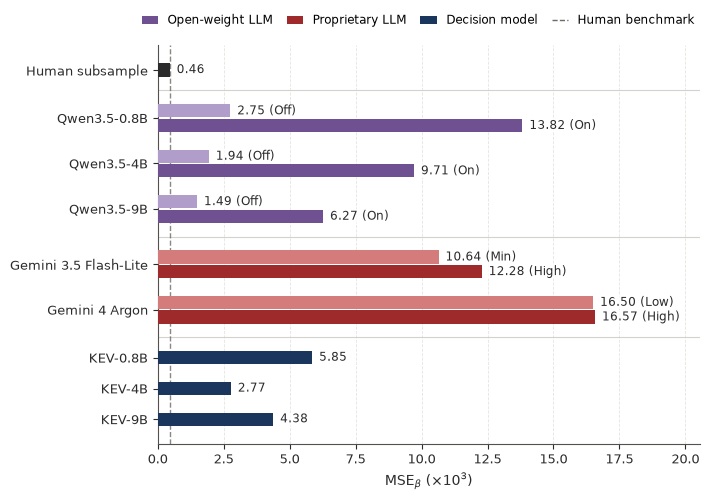

In [8]:
summary_df = pd.read_csv(SUMMARY_CSV)


def mse_for(family, model, config, readout):
    mask = (summary_df["family"] == family) & (summary_df["model"] == model)
    mask = mask & (summary_df["persona"] == PERSONA) & (summary_df["readout"] == readout)
    if config is not None:
        mask = mask & (summary_df["config"] == config)
    matches = summary_df[mask]
    if len(matches) != 1:
        raise ValueError(f"Expected 1 row in {SUMMARY_CSV} for {model}/{config}/{readout}, got {len(matches)}")
    mse = float(matches["beta_mse_x1e3"].iloc[0])
    if not np.isfinite(mse):
        raise ValueError(f"Non-finite beta_mse_x1e3 for {model}/{config}/{readout}")
    return mse


# Bar positions: tight within a model, wider gaps between models and between families.
bars = []
model_centers = []
model_labels = []
family_dividers = []
reference_mse = None
y_cursor = 0.0
previous_family = None
for group_label, family, entries in BAR_GROUPS:
    if previous_family is not None:
        if family != previous_family:
            family_dividers.append(y_cursor + BETWEEN_FAMILIES / 2.0 - IN_GROUP_STEP / 2.0)
            y_cursor += BETWEEN_FAMILIES
        else:
            y_cursor += BETWEEN_MODELS
    bar_ys = []
    for entry_index, (tag, selector, color) in enumerate(entries):
        bar_y = y_cursor + entry_index * IN_GROUP_STEP
        mse = mse_for(*selector)
        bars.append((bar_y, mse, color, tag))
        bar_ys.append(bar_y)
        if group_label == REFERENCE_GROUP:
            reference_mse = mse
    model_centers.append(float(np.mean(bar_ys)))
    model_labels.append(group_label)
    y_cursor = bar_ys[-1] + IN_GROUP_STEP
    previous_family = family
if reference_mse is None:
    raise ValueError(f"REFERENCE_GROUP {REFERENCE_GROUP!r} is not in BAR_GROUPS")

max_mse = max(bar[1] for bar in bars)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, max(4.4, y_cursor * 0.54)))

ax.axvline(reference_mse, color=REF_LINE_COLOR, linestyle="--", linewidth=1.0, alpha=0.8, zorder=2)
for divider_y in family_dividers:
    ax.axhline(divider_y, color=GRID_COLOR, linewidth=0.8, linestyle="-", zorder=1)

for bar_y, mse, color, tag in bars:
    ax.barh(bar_y, mse, height=BAR_HEIGHT, color=color, edgecolor="none", zorder=3)
    if tag:
        value_text = f"{mse:.2f} ({tag})"
    else:
        value_text = f"{mse:.2f}"
    ax.text(
        mse + max_mse * 0.016,
        bar_y,
        value_text,
        va="center",
        fontsize=VALUE_LABEL_SIZE,
        color=TEXT_COLOR,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.4, "alpha": 0.75},
        zorder=4,
    )

ax.set_yticks(model_centers)
ax.set_yticklabels(model_labels, fontsize=MODEL_LABEL_SIZE, color=TEXT_COLOR)
ax.invert_yaxis()
ax.set_xlabel(X_LABEL, fontsize=X_LABEL_SIZE, color=TEXT_COLOR)
ax.set_xlim(0, max_mse * 1.24)
ax.grid(axis="x", color=GRID_COLOR, linestyle="--", linewidth=0.6, alpha=0.6, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(MUTED_COLOR)
ax.spines["bottom"].set_color(MUTED_COLOR)
ax.tick_params(colors=TEXT_COLOR, labelsize=TICK_LABEL_SIZE)

legend_handles = []
for kind, color, text in LEGEND_ENTRIES:
    if kind == "patch":
        legend_handles.append(matplotlib.patches.Patch(facecolor=color, label=text))
    elif kind == "line":
        legend_handles.append(matplotlib.lines.Line2D([0], [0], color=color, linestyle="--", linewidth=1.0, label=text))
    else:
        raise ValueError(f"Unknown legend entry kind {kind!r}")
ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.48, 1.02),
    ncol=len(legend_handles),
    frameon=False,
    fontsize=LEGEND_SIZE,
    columnspacing=1.2,
    handlelength=1.4,
)
fig.tight_layout()
print(f"Human subsample reference: {reference_mse:.2f}")

## Save `fig-intro-off-the-shelf.png` and `.pdf` (the manuscript points here)

In [9]:
for extension in ("png", "pdf"):
    figure_path = ASSET_DIR / f"{ASSET_NAME}.{extension}"
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    print(f"Saved {figure_path}")
plt.show()

Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-intro-off-the-shelf.png
Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-intro-off-the-shelf.pdf
